In [1]:
from astropy.io import fits
from astropy.table import Table
import astropy.units as u
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

#### MAGIC Paper

In [2]:
magic = "../MAGIC_2020_B0218.fits"
hdu_map = {
    ("C", "obs"): 11,
    ("C", "int"): 12,
    ("D", "obs"): 13,
    ("D", "int"): 14,
}

magic_sed = {}
for (period, state), hdu in hdu_map.items():
    table = Table.read(magic, hdu=hdu)
    magic_sed[(period, state)] = Table({
        "energy": table["energy"].value * u.Unit("GeV"),
        "nuFnu": table["flux"].value * u.Unit("TeV cm-2 s-1"),
        "nuFnu_err": table["Denergy"].value * u.Unit("TeV cm-2 s-1"),
    })
    # print(f"Period {period} ({state}):\n", magic_sed[(period, state)], "\n")

#### Analysis Result

In [3]:
analysis = {
    "obs": "./MAGIC_sed_flux_points_obs.fits",
    "int": "./MAGIC_sed_flux_points_intrinsic.fits",
}

my_sed = {}
for state, path in analysis.items():
    sed = Table.read(path, hdu=1)
    my_sed[state] = Table({
        "energy": sed["e_ref"].to(u.GeV),
        "nuFnu": sed["e2dnde"].to(u.TeV / (u.s * u.cm**2)),
        "nuFnu_err": sed["e2dnde_errn"].to(u.TeV / (u.s * u.cm**2)),
        "nuFnu_errp": sed["e2dnde_errp"].to(u.TeV / (u.s * u.cm**2)),
    })
    # print(f"MAGIC SED ({state}):\n", my_sed[state], "\n")

#### Compare Plot

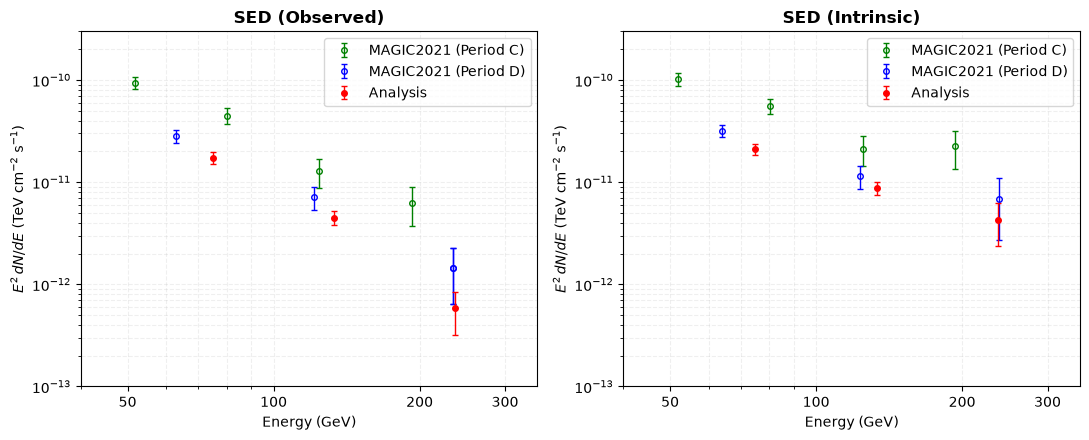

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
paper_colors = {"C": "green", "D": "blue"}

for ax, state, title in zip(axes, ["obs", "int"], ["Observed", "Intrinsic"]):
    for period, color in paper_colors.items():
        paper = magic_sed[(period, state)]
        ax.errorbar(
            paper["energy"].value,
            paper["nuFnu"].value,
            yerr=paper["nuFnu_err"].value,
            fmt="o",
            markersize=4,
            mfc="none",
            capsize=2,
            elinewidth=1,
            capthick=1,
            color=color,
            label=f"MAGIC2021 (Period {period})",
        )

    mine = my_sed[state]
    ax.errorbar(
        mine["energy"].value,
        mine["nuFnu"].value,
        yerr=[mine["nuFnu_err"].value, mine["nuFnu_errp"].value],
        fmt="o",
        markersize=4,
        capsize=2,
        elinewidth=1,
        capthick=1,
        color="red",
        label="Analysis",
    )

    ax.set_title(f"SED ({title})", fontweight="bold")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xticks([50, 100, 200, 300])
    ax.xaxis.set_major_formatter(ticker.ScalarFormatter())
    ax.xaxis.set_minor_formatter(ticker.NullFormatter())
    ax.set_xlabel("Energy (GeV)")
    ax.set_xlim(40, 350)
    ax.set_ylim(1e-13, 3e-10)
    ax.grid(True, which="both", ls="--", alpha=0.2)
    ax.legend(frameon=True)

axes[0].set_ylabel(r"$E^2\,dN/dE$ (TeV cm$^{-2}$ s$^{-1}$)")
axes[1].set_ylabel(r"$E^2\,dN/dE$ (TeV cm$^{-2}$ s$^{-1}$)")

plt.tight_layout()
# plt.savefig("compare_oq334.pdf")
plt.savefig("compare_oq334.png")
plt.show()